In [189]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [190]:
df = pd.read_csv("Food_Delivery_Times.csv")

In [191]:
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [192]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


In [193]:
df.isnull().sum() / 100

Order_ID                  0.0
Distance_km               0.0
Weather                   0.3
Traffic_Level             0.3
Time_of_Day               0.3
Vehicle_Type              0.0
Preparation_Time_min      0.0
Courier_Experience_yrs    0.3
Delivery_Time_min         0.0
dtype: float64

In [194]:
df.dropna(subset=['Weather','Traffic_Level','Time_of_Day','Courier_Experience_yrs'], inplace=True)

In [195]:
df.isnull().sum() / 100

Order_ID                  0.0
Distance_km               0.0
Weather                   0.0
Traffic_Level             0.0
Time_of_Day               0.0
Vehicle_Type              0.0
Preparation_Time_min      0.0
Courier_Experience_yrs    0.0
Delivery_Time_min         0.0
dtype: float64

In [196]:
df.describe()

,Order_ID,Distance_km,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
count,883.000000,883.000000,883.000000,883.000000,883.000000
mean,508.109853,10.051586,17.019253,4.639864,56.425821
std,287.925161,5.688582,7.260201,2.922172,21.568482
min,1.000000,0.590000,5.000000,0.000000,8.000000
25%,263.500000,5.130000,11.000000,2.000000,41.000000
50%,512.000000,10.280000,17.000000,5.000000,55.000000
75%,758.500000,15.025000,23.000000,7.000000,71.000000
max,1000.000000,19.990000,29.000000,9.000000,141.000000


In [197]:
df['Weather'].value_counts().unique     #ohe

<bound method Series.unique of Weather
Clear    425
Rainy    188
Foggy     98
Windy     86
Snowy     86
Name: count, dtype: int64>

In [198]:
df['Vehicle_Type'].value_counts().unique    # ohe

<bound method Series.unique of Vehicle_Type
Bike       451
Scooter    260
Car        172
Name: count, dtype: int64>

In [199]:
df['Time_of_Day'].value_counts().unique         # ordinal encoding

<bound method Series.unique of Time_of_Day
Morning      281
Evening      269
Afternoon    257
Night         76
Name: count, dtype: int64>

In [200]:
df['Traffic_Level'].value_counts().unique       # ordinal encoding

<bound method Series.unique of Traffic_Level
Medium    355
Low       347
High      181
Name: count, dtype: int64>

In [201]:
#df['Delivery_Time_min'] that is a output column 

<Axes: xlabel='Weather', ylabel='Delivery_Time_min'>

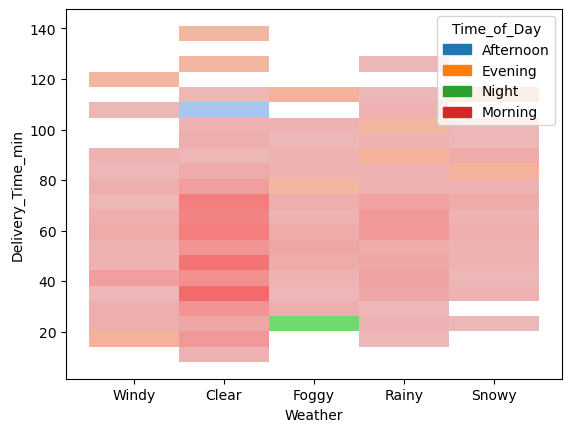

In [202]:
sns.histplot(x = df['Weather'], y = df['Delivery_Time_min'],hue=df['Time_of_Day'])

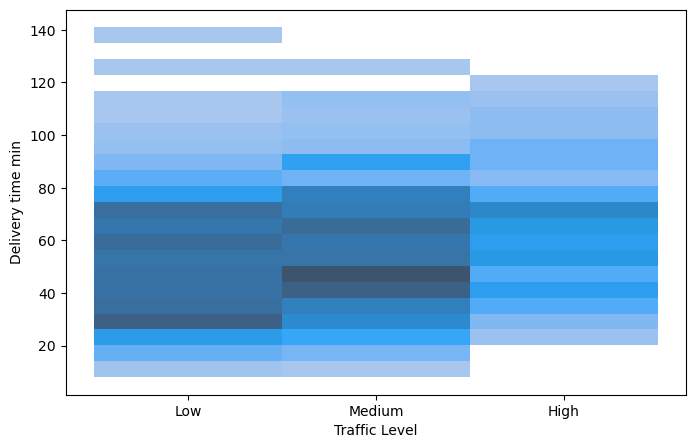

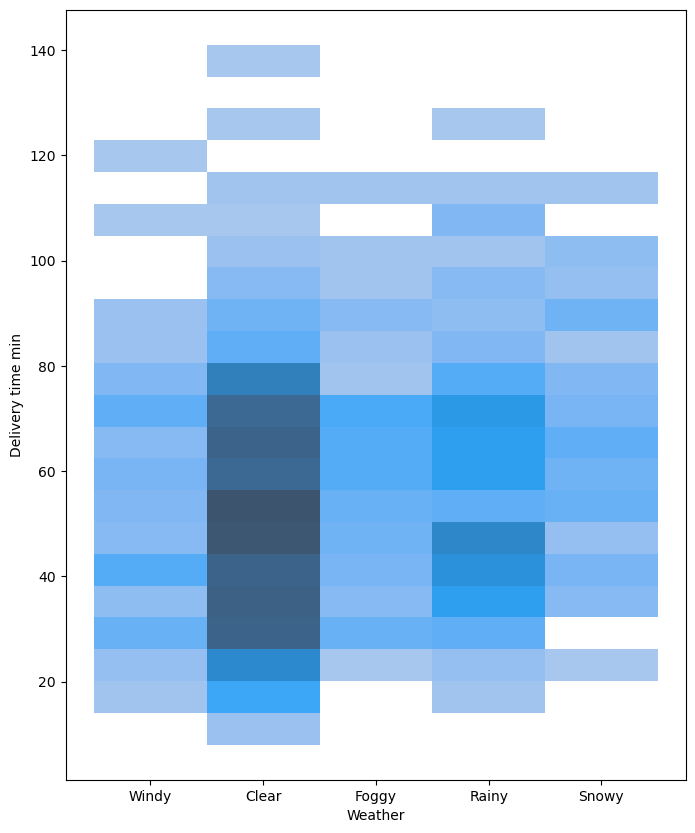

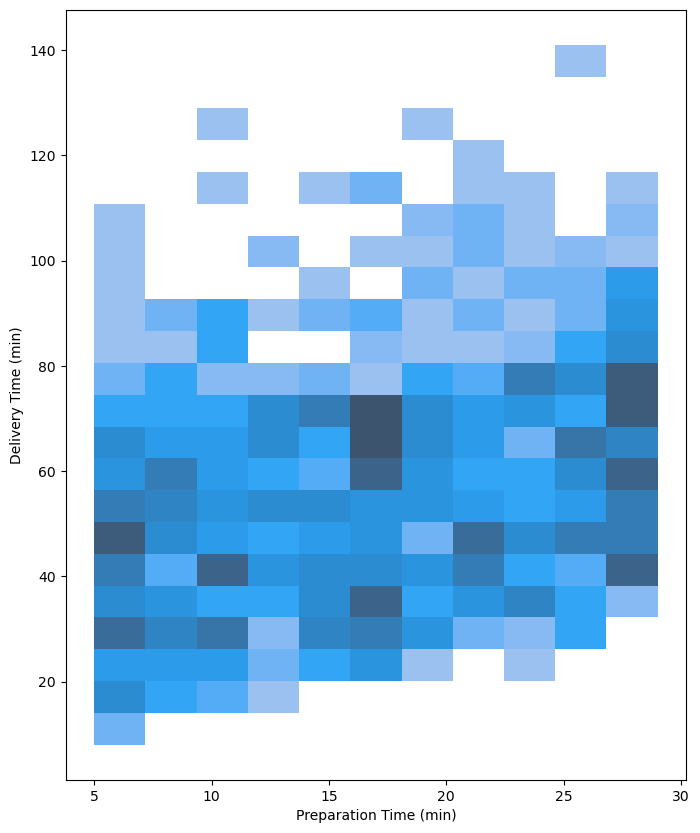

In [203]:
plt.figure(figsize=(8,5))
sns.histplot(x = df['Traffic_Level'],y = df['Delivery_Time_min'])
plt.xlabel("Traffic Level")
plt.ylabel("Delivery time min")

plt.figure(figsize=(8,10))
sns.histplot(x = df['Weather'],y = df['Delivery_Time_min'])
plt.xlabel("Weather")
plt.ylabel("Delivery time min")
plt.show()

plt.figure(figsize=(8,10))
sns.histplot(x = df['Preparation_Time_min'],y = df['Delivery_Time_min'])
plt.xlabel("Preparation Time (min)")
plt.ylabel("Delivery Time (min)")
plt.show()


<Axes: xlabel='Preparation_Time_min', ylabel='Delivery_Time_min'>

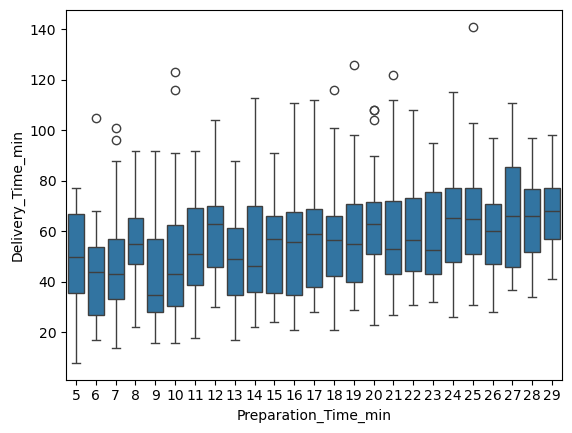

In [204]:
sns.boxplot(x = df['Preparation_Time_min'],y = df['Delivery_Time_min'])

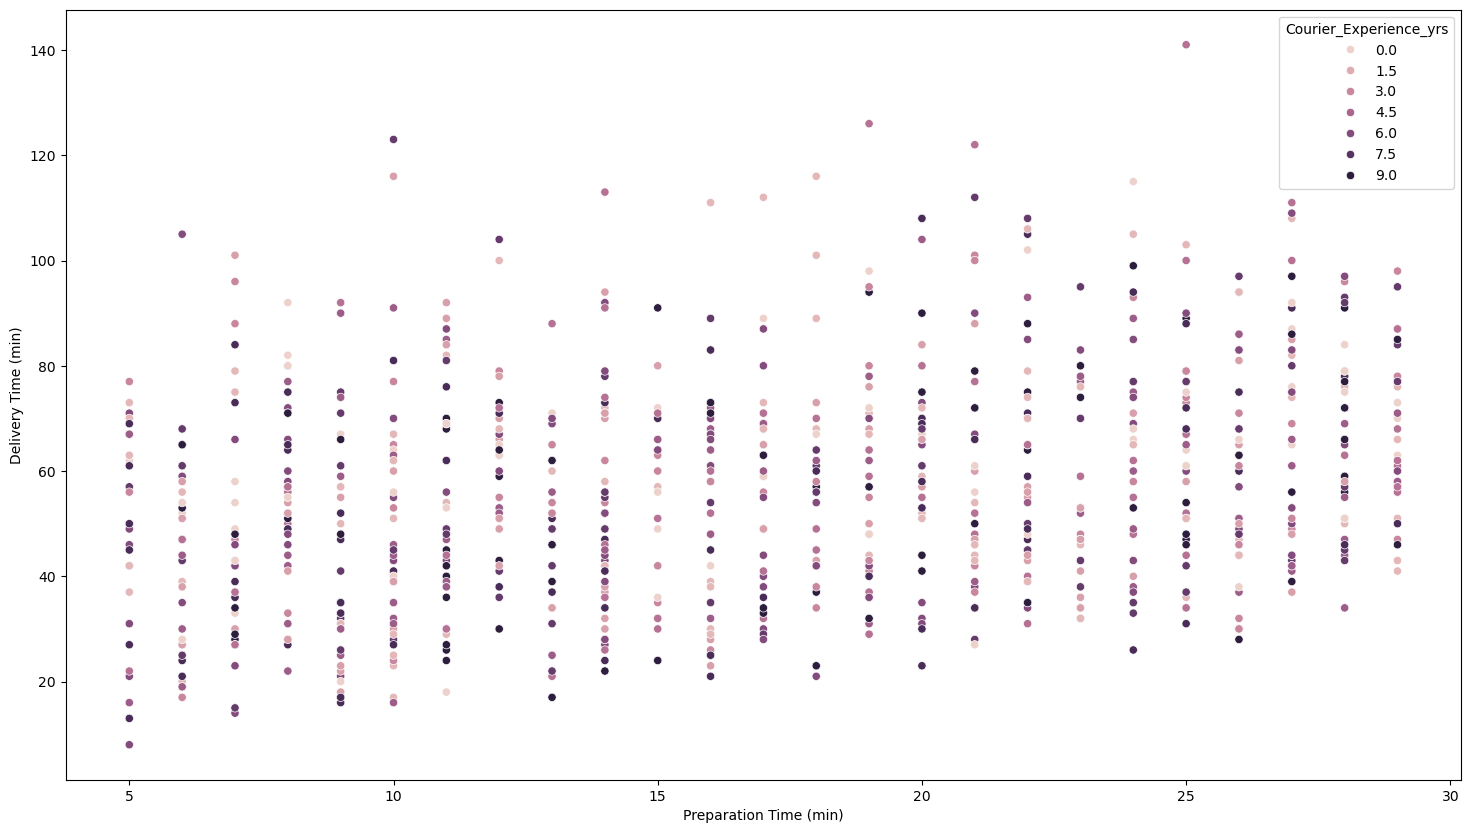

In [205]:
plt.figure(figsize=(18,10))
sns.scatterplot(x = df['Preparation_Time_min'],y = df['Delivery_Time_min'],hue=df['Courier_Experience_yrs'])
plt.xlabel("Preparation Time (min)")
plt.ylabel("Delivery Time (min)")
plt.show()

In [206]:
df.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


In [207]:
X = df.drop(['Delivery_Time_min'], axis=1)
y = df['Delivery_Time_min']

In [208]:
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer

In [209]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [210]:
transformer = ColumnTransformer(transformers=[
    ('ohe', OneHotEncoder(drop='first',sparse_output=False), ['Weather', 'Vehicle_Type']),
    ('ordinal1', OrdinalEncoder(categories=[['Low', 'Medium', 'High']]), ['Traffic_Level']),
    ('ordinal2', OrdinalEncoder(categories=[['Morning', 'Afternoon', 'Evening','Night']]), ['Time_of_Day']),
],remainder='passthrough')

In [211]:
X_train_trans = transformer.fit_transform(X_train)
X_test_trans = transformer.transform(X_test)

In [212]:
transformer

,transformers,"[('ohe', ...), ('ordinal1', ...), ...]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,categories,'auto'
,drop,'first'
,sparse_output,False


In [213]:
transformer.get_params

<bound method ColumnTransformer.get_params of ColumnTransformer(remainder='passthrough',
                  transformers=[('ohe',
                                 OneHotEncoder(drop='first',
                                               sparse_output=False),
                                 ['Weather', 'Vehicle_Type']),
                                ('ordinal1',
                                 OrdinalEncoder(categories=[['Low', 'Medium',
                                                             'High']]),
                                 ['Traffic_Level']),
                                ('ordinal2',
                                 OrdinalEncoder(categories=[['Morning',
                                                             'Afternoon',
                                                             'Evening',
                                                             'Night']]),
                                 ['Time_of_Day'])])>

In [214]:
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor


In [215]:
lr = LinearRegression()
lr.fit(X_train_trans, y_train)
y_pred = lr.predict(X_test_trans)

print("R-squared:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Cross-Validation Scores:", cross_val_score(lr, X_train_trans, y_train, cv=5, scoring='r2').mean())

R-squared: 0.8176422153320309
Mean Squared Error: 80.40334038225369
Mean Absolute Error: 5.7236891088635335
Cross-Validation Scores: 0.7553257837800451


In [216]:
r = Ridge(alpha=1.0)
r.fit(X_train_trans, y_train)
y_pred5 = r.predict(X_test_trans)

print("R-squared:", r2_score(y_test, y_pred5))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred5))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred5))
print("Cross-Validation Scores:", cross_val_score(r, X_train_trans, y_train, cv=5, scoring='r2').mean())

R-squared: 0.8174556897292616
Mean Squared Error: 80.48558135461892
Mean Absolute Error: 5.729340927302048
Cross-Validation Scores: 0.7553954028779833


In [217]:
l = Lasso(alpha=0.1)
l.fit(X_train_trans, y_train)
y_pred6 = l.predict(X_test_trans)

print("R-squared:", r2_score(y_test, y_pred6))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred6))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred6))
print("Cross-Validation Scores:", cross_val_score(l, X_train_trans, y_train, cv=5, scoring='r2').mean())

R-squared: 0.8143205200807357
Mean Squared Error: 81.86790848074357
Mean Absolute Error: 5.818926310221965
Cross-Validation Scores: 0.7542418234006029


In [218]:
e = ElasticNet(alpha=0.1, l1_ratio=0.5)
e.fit(X_train_trans, y_train)
y_pred7 = e.predict(X_test_trans)

print("R-squared:", r2_score(y_test, y_pred7))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred7))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred7))
print("Cross-Validation Scores:", cross_val_score(e, X_train_trans, y_train, cv=5, scoring='r2').mean())

R-squared: 0.8076616567322741
Mean Squared Error: 84.80386680761244
Mean Absolute Error: 6.047843301319407
Cross-Validation Scores: 0.7503409374652804


In [219]:
lr2 = LogisticRegression()
lr2.fit(X_train_trans, y_train)
y_pred2 = lr2.predict(X_test_trans)

print("R-squared:", r2_score(y_test, y_pred2))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred2))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred2))
print("Cross-Validation Scores:", cross_val_score(lr2, X_train_trans, y_train, cv=5, scoring='r2').mean())

d:\Notebook\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
d:\Notebook\Lib\site-packages\sklearn\model_selection\_split.py:811: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
d:\Notebook\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the c

R-squared: 0.2600683262764839
Mean Squared Error: 326.2431506849315
Mean Absolute Error: 14.106164383561644


d:\Notebook\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
d:\Notebook\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation f

Cross-Validation Scores: 0.2883833436117825


d:\Notebook\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
d:\Notebook\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation f

In [220]:
rfr = RandomForestRegressor(n_estimators=500,min_samples_leaf=2,min_samples_split=4,n_jobs=-1,random_state=42)
rfr.fit(X_train_trans, y_train)
y_pred3 = rfr.predict(X_test_trans)
print("R-squared :", r2_score(y_test, y_pred3))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred3))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred3))
print("Cross-Validation Scores:", cross_val_score(rfr, X_train_trans, y_train, cv=5, scoring='r2').mean())

R-squared : 0.7507855874364457
Mean Squared Error: 109.88108502192419
Mean Absolute Error: 7.356560826711341
Cross-Validation Scores: 0.6870563767942622


In [221]:
dt = DecisionTreeRegressor(min_samples_leaf=2,min_samples_split=4,random_state=42)
dt.fit(X_train_trans, y_train)
y_pred4 = dt.predict(X_test_trans)
print("R-squared :", r2_score(y_test, y_pred4))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred4))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred4))
print("Cross-Validation Scores:", cross_val_score(dt, X_train_trans, y_train, cv=5, scoring='r2').mean())

R-squared : 0.4936584884484183
Mean Squared Error: 223.25095129375953
Mean Absolute Error: 10.665525114155251
Cross-Validation Scores: 0.46601737662902093


In [222]:
knn = KNeighborsRegressor(n_neighbors=5,weights='distance',n_jobs=-1,leaf_size=50)
knn.fit(X_train_trans, y_train)
y_pred4 = knn.predict(X_test_trans)
print("R-squared :", r2_score(y_test, y_pred4))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred4))
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred4))
print("Cross-Validation Scores:", cross_val_score(knn, X_train_trans, y_train, cv=5, scoring='r2').mean())

R-squared : 0.4657772350020364
Mean Squared Error: 235.54407009433623
Mean Absolute Error: 12.010481415086913
Cross-Validation Scores: 0.3865175834642868
